# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import BHWatertanksDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 145


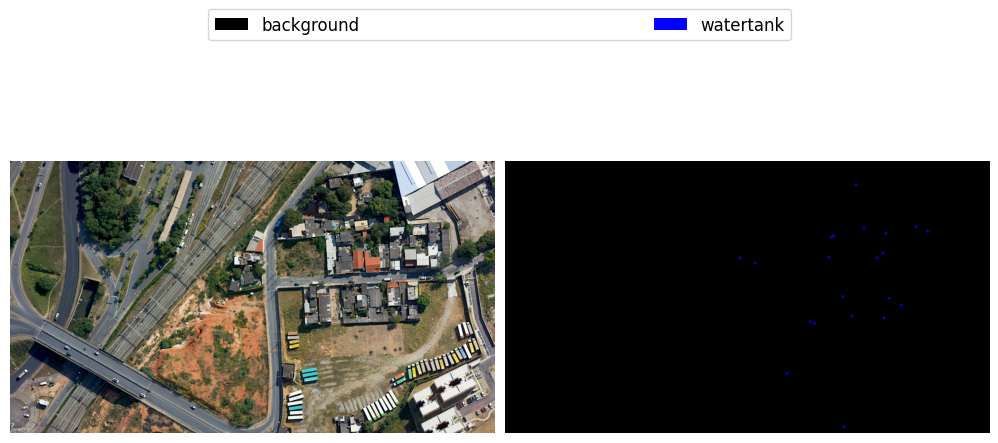

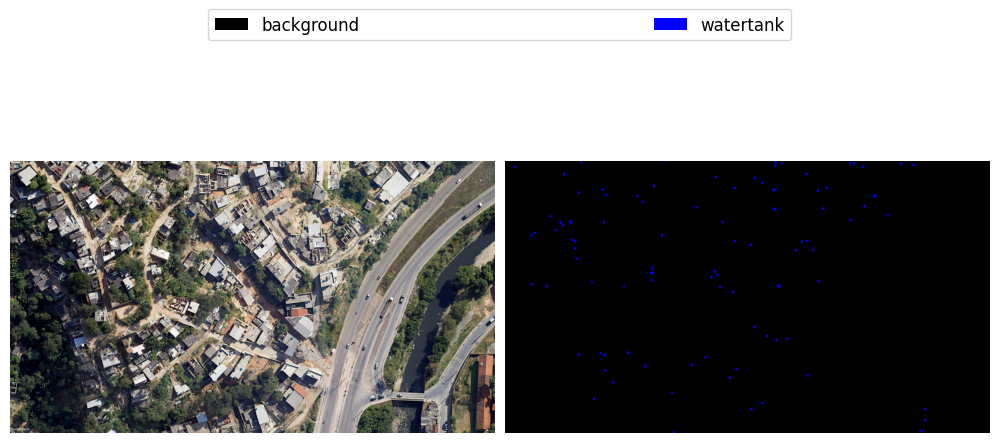

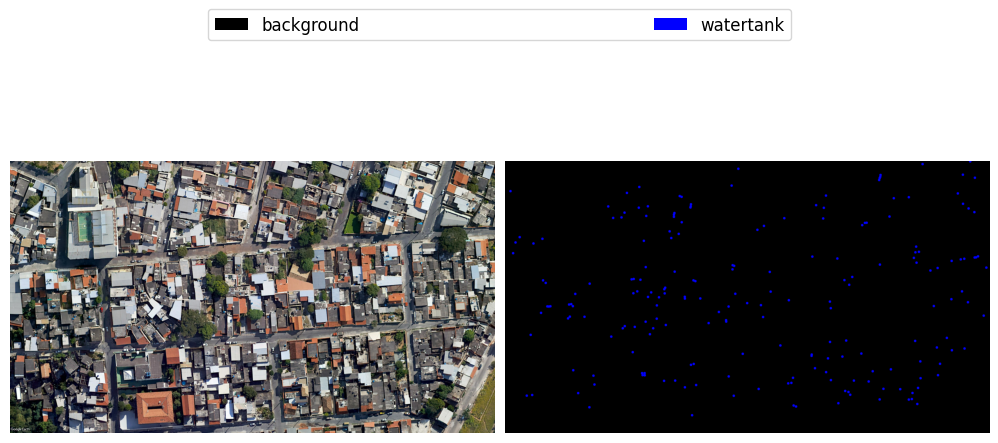

In [ ]:
dataset_config = {
    "data_dir": "./data/BH-Watertanks/train"
}
dataset = BHWatertanksDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(140);

In [9]:
dataset.data_distribution_table()

,Number of pixels
background,1.197707e+09
watertank,4.981251e+06


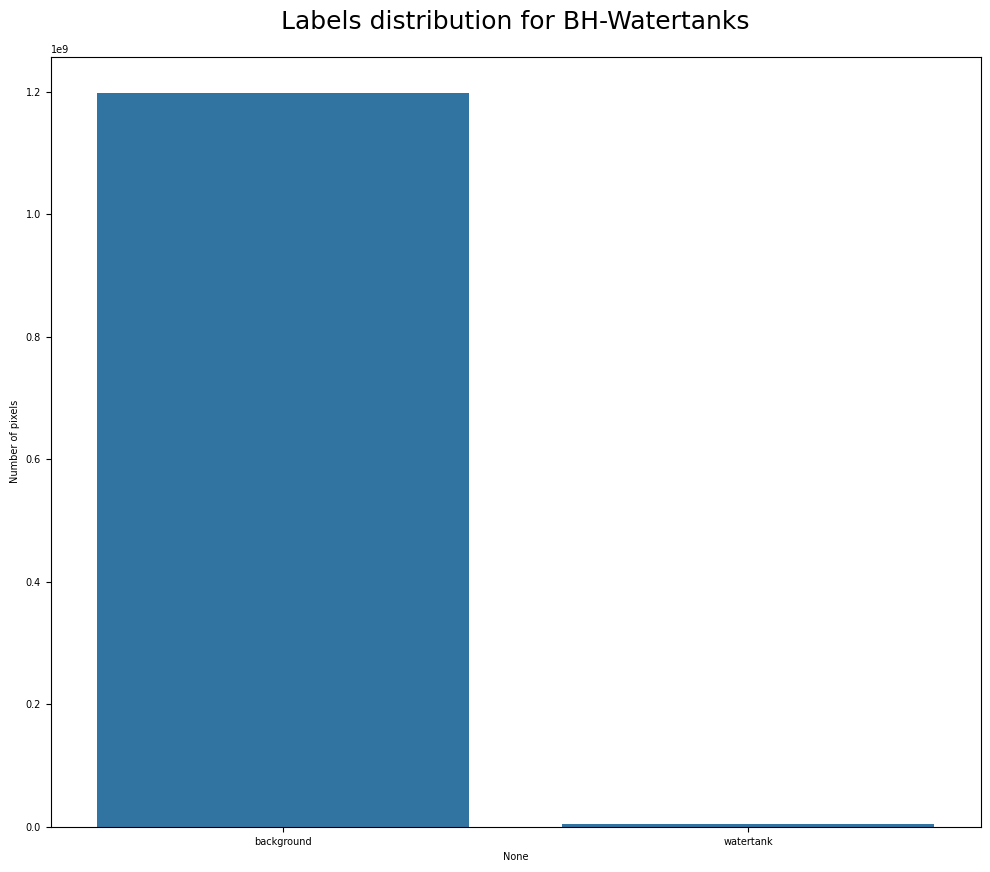

In [10]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 5,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/BH-Watertanks/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = BHWatertanksDataset(train_dataset_config)
len(train_dataset)

145

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/BH-Watertanks/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-05 08:52:38,224 INFO Starting training.
training: 100%|██████████| 29/29 [15:04<00:00, 31.20s/it]
2025-03-05 09:07:43,056 INFO epoch: 1, time: 905, loss:  0.45067
testing on train set: 100%|██████████| 29/29 [15:06<00:00, 31.25s/it]
2025-03-05 09:22:51,078 INFO IOU:0.3033150435333901, IOU mean:0.248139161002772, IOU per Class:[4.96277822e-01 5.00369606e-07]
training: 100%|██████████| 29/29 [14:59<00:00, 31.02s/it]
2025-03-05 09:37:50,786 INFO epoch: 2, time: 899, loss:  0.35841
testing on train set: 100%|██████████| 29/29 [14:59<00:00, 31.02s/it]
2025-03-05 09:52:50,501 INFO IOU:0.5869948679490924, IOU mean:0.4718776537999945, IOU per Class:[9.43754788e-01 5.19505438e-07]
training: 100%|██████████| 29/29 [15:20<00:00, 31.75s/it]
2025-03-05 10:08:11,201 INFO epoch: 3, time: 921, loss:  0.30279
testing on train set: 100%|██████████| 29/29 [15:53<00:00, 32.87s/it]
2025-03-05 10:24:04,430 INFO IOU:0.9218578499670237, IOU mean:0.4823256627377868, IOU per Class:[9.64649058e-01 2.2671

## Predictions

2025-03-10 09:35:34,311 INFO Loading checkpoint /home/dragik/data/FAIR_EO/BH-Watertanks/checkpoint.pth.tar
2025-03-10 09:35:34,820 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/BH-Watertanks/checkpoint.pth.tar at epoch 11


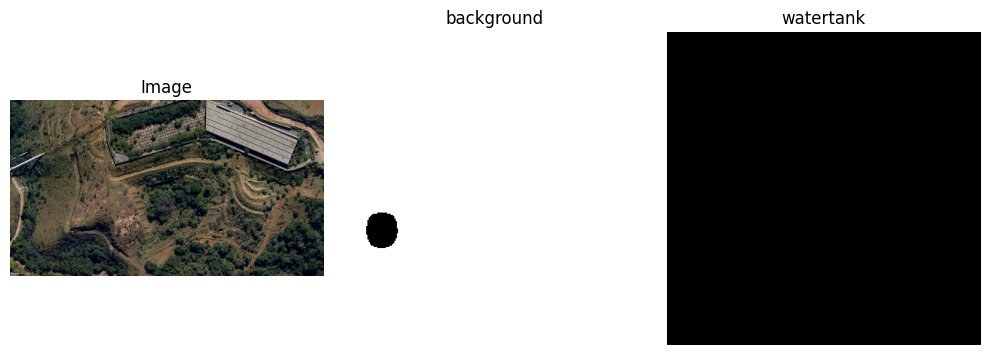

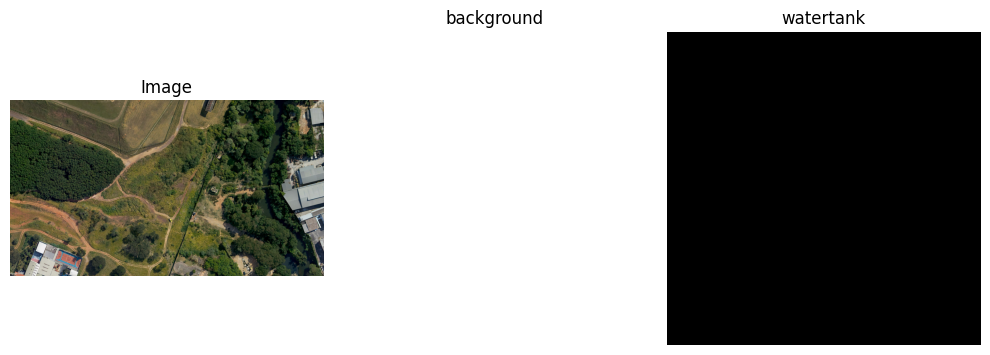

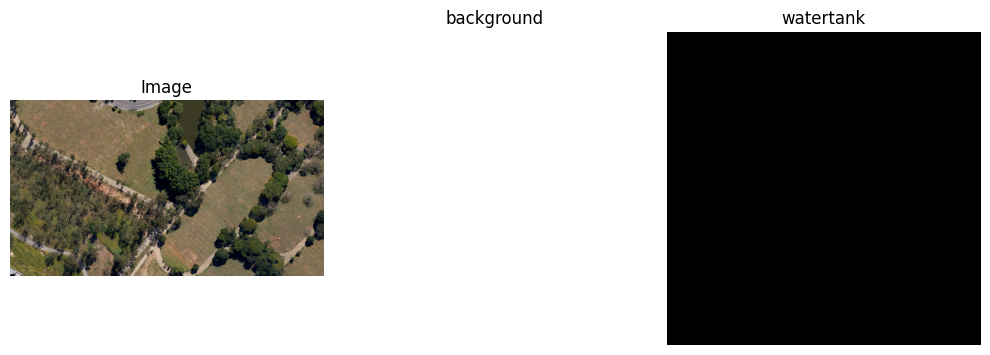

In [ ]:
model_path = "./data/BH-Watertanks/checkpoint.pth.tar"
labels = ["background","watertank"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/BH-Watertanks/test/images/REGION_2_21.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BH-Watertanks/test/images/REGION_4_1.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BH-Watertanks/test/images/REGION_6_8.jpg')
fig = model.predict_masks(image, labels, transform)